In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [4]:
DEMAND_TORONTO_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/XTMF Executions/RunUpdatedDemandMatrices-2026.11.16-VISUM2024/Demand'
SKIMS_TORONTO_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/XTMF Executions/RunUpdatedDemandMatrices-2026.11.16-VISUM2024/Los Matrices'

In [2]:
def read_matrix(path, value_name):
    df = pd.read_csv(path)

    df = df.rename(columns={"Data": value_name})

    df["Origin"] = pd.to_numeric(df["Origin"])
    df["Destination"] = pd.to_numeric(df["Destination"])
    df[value_name] = pd.to_numeric(df[value_name], errors="coerce")

    return df[["Origin", "Destination", value_name]]

In [8]:
periods = ["EM", "AP"]

distance_files = {
    "EM": "adist.mtx.csv",
    "AP": "aDistance.mtx.csv"
}

# Cambiar a "m" si adistance está en metros
DISTANCE_UNIT = "km"

bins_time = [0, 6, 10, 15, 30, 45, 60, 90, 120, np.inf]

labels_time = [
    "0-6", "6-10", "10-15", "15-30",
    "30-45", "45-60", "60-90", "90-120", "120+"
]

def prepare_time_distance_data(period):

    keys = ["Origin", "Destination"]

    # 1. Demanda Auto
    demand = read_matrix(
        os.path.join(
            DEMAND_TORONTO_FOLDER,
            f"Auto{period}.mtx.csv"
        ),
        "demand"
    )

    demand = demand[demand["demand"] > 0].copy()

    # 2. Skim de tiempos
    time = read_matrix(
        os.path.join(
            SKIMS_TORONTO_FOLDER,
            period,
            "aivtt.mtx.csv"
        ),
        "travel_time"
    )

    # 3. Skim de distancias
    distance = read_matrix(
        os.path.join(
            SKIMS_TORONTO_FOLDER,
            period,
            distance_files[period]
        ),
        "distance"
    )

    # 4. Cruzar las tres matrices
    df = (
        demand
        .merge(time, on=keys, how="left", validate="one_to_one")
        .merge(distance, on=keys, how="left", validate="one_to_one")
    )

    # 5. Excluir intrazonales y valores inválidos
    valid = (
        (df["Origin"] != df["Destination"]) &
        (df["travel_time"] > 0) &
        np.isfinite(df["travel_time"]) &
        (df["distance"] > 0) &
        np.isfinite(df["distance"])
    )

    viajes_total = df["demand"].sum()
    viajes_validos = df.loc[valid, "demand"].sum()

    print(
        f"{period}: {viajes_validos:,.0f} viajes incluidos "
        f"({viajes_validos/viajes_total*100:.1f}% del total)"
    )

    df = df.loc[valid].copy()

    # 6. Convertir distancia a km
    if DISTANCE_UNIT == "m":
        df["distance_km"] = df["distance"] / 1000
    elif DISTANCE_UNIT == "km":
        df["distance_km"] = df["distance"]
    else:
        raise ValueError("DISTANCE_UNIT debe ser 'km' o 'm'")

    # 7. Velocidad OD (km/h)
    df["speed_kmh"] = (
        df["distance_km"] /
        df["travel_time"] * 60
    )

    # 8. Clasificar por intervalo de tiempo
    df["time_bin"] = pd.cut(
        df["travel_time"],
        bins=bins_time,
        labels=labels_time,
        right=False
    )

    df["period"] = period

    return df


In [9]:

def weighted_avg(values, weights):
    if weights.sum() == 0:
        return np.nan
    return np.average(values, weights=weights)


def summarize_time_distance(df):

    results = []

    total_demand = df["demand"].sum()

    for time_bin, group in df.groupby(
        "time_bin",
        observed=False
    ):

        if group.empty:
            continue

        weights = group["demand"]

        avg_time = weighted_avg(
            group["travel_time"], weights
        )

        avg_distance = weighted_avg(
            group["distance_km"], weights
        )

        avg_speed = weighted_avg(
            group["speed_kmh"], weights
        )

        # Velocidad agregada = distancia total / tiempo total
        aggregate_speed = avg_distance / avg_time * 60

        results.append({
            "Time bin": str(time_bin),
            "Trips": weights.sum(),
            "% Trips": weights.sum() / total_demand * 100,
            "Avg time (min)": avg_time,
            "Avg distance (km)": avg_distance,
            "Avg OD speed (km/h)": avg_speed,
            "Aggregate speed (km/h)": aggregate_speed
        })

    return pd.DataFrame(results)


datos_por_periodo = {}
tablas_por_periodo = {}

for period in periods:

    df = prepare_time_distance_data(period)

    datos_por_periodo[period] = df
    tablas_por_periodo[period] = summarize_time_distance(df)

    print(f"\n========== {period} ==========")
    display(tablas_por_periodo[period].round(2))


EM: 1,153 viajes incluidos (100.0% del total)

========== EM ==========


,Time bin,Trips,% Trips,Avg time (min),Avg distance (km),Avg OD speed (km/h),Aggregate speed (km/h)
0,0-6,299.99,26.01,4.72,1.59,19.09,20.26
1,6-10,53.35,4.63,9.89,4.68,28.43,28.42
2,10-15,137.88,11.96,13.96,8.89,37.78,38.23
3,15-30,617.62,53.56,19.66,14.16,42.93,43.21
4,30-45,44.10,3.82,40.99,38.43,56.23,56.24
5,45-60,0.25,0.02,48.22,42.93,53.60,53.41


AP: 383,080 viajes incluidos (96.5% del total)

========== AP ==========


,Time bin,Trips,% Trips,Avg time (min),Avg distance (km),Avg OD speed (km/h),Aggregate speed (km/h)
0,0-6,34068.01,8.89,4.60,1.30,16.65,17.02
1,6-10,66773.50,17.43,7.96,2.81,21.01,21.20
2,10-15,62993.18,16.44,12.57,5.21,24.72,24.88
3,15-30,126637.33,33.06,21.95,10.76,29.15,29.43
4,30-45,47940.91,12.51,36.23,18.64,30.91,30.87
5,45-60,25875.23,6.75,51.26,26.62,31.07,31.16
6,60-90,13777.93,3.60,69.27,35.19,30.43,30.47
7,90-120,4185.15,1.09,102.40,33.26,19.50,19.48
8,120+,829.15,0.22,127.60,61.10,28.73,28.73


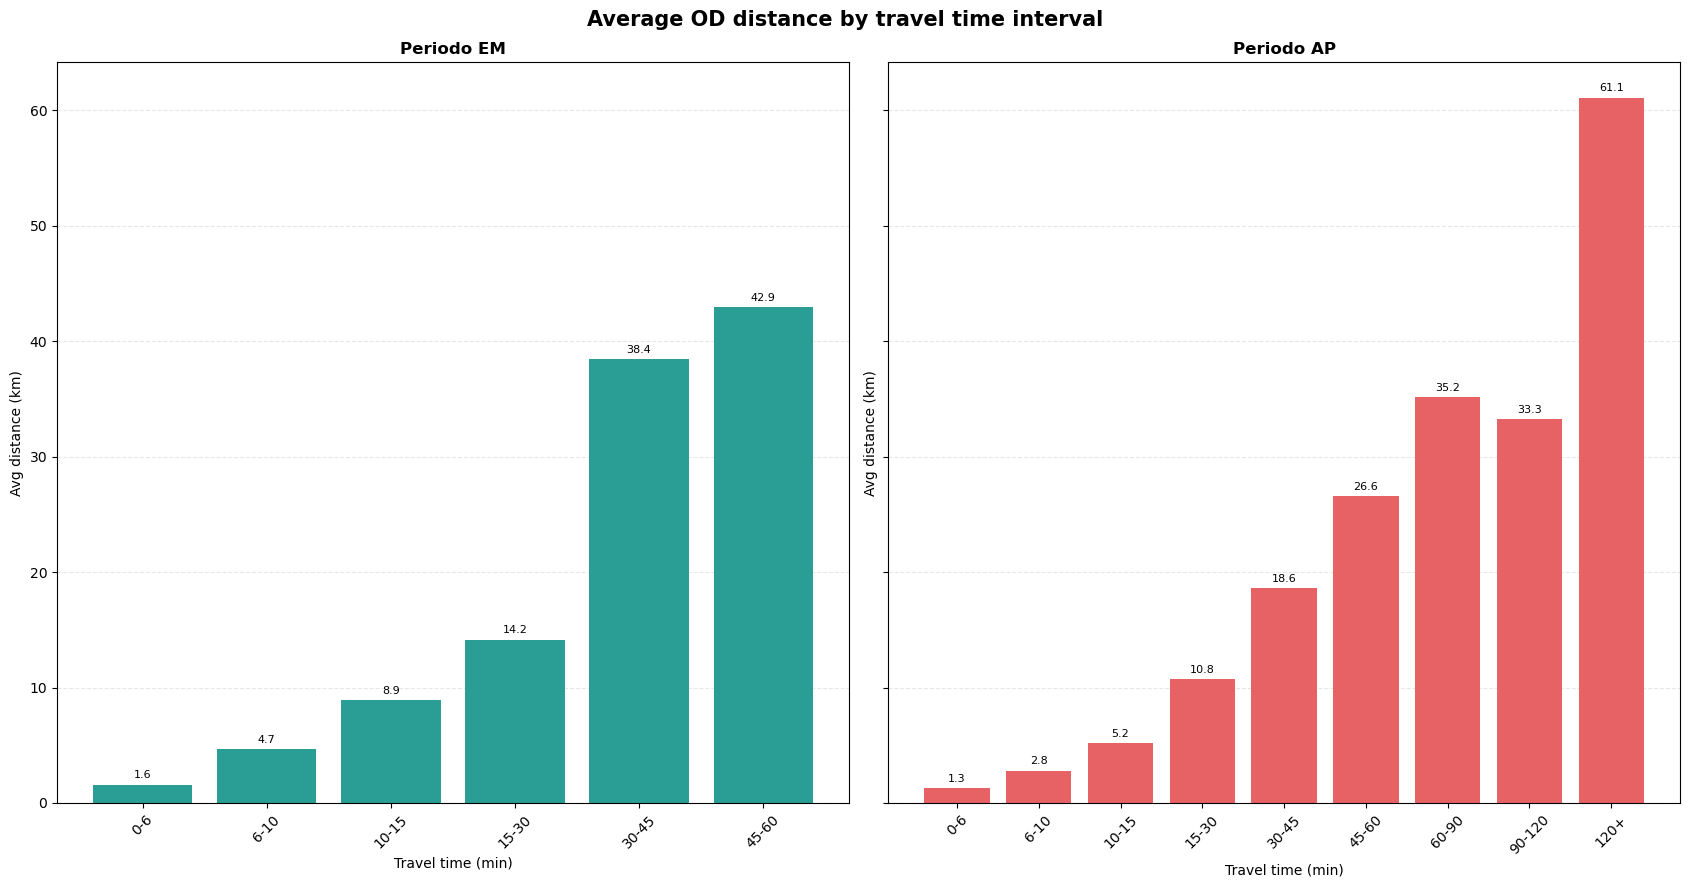

In [10]:

colores_periodo = {
    "EM": "#2A9D94",
    "AP": "#E76265",
    "LM": "#E78A2E",
    "EA": "#5FB951",
    "PP": "#AA518F",
    "LN": "#4384C9",
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 9),
    sharey=True
)

for ax, period in zip(axes.flat, periods):

    tabla = tablas_por_periodo[period]

    bars = ax.bar(
        tabla["Time bin"],
        tabla["Avg distance (km)"],
        color=colores_periodo[period]
    )

    ax.set_title(
        f"Periodo {period}",
        fontweight="bold"
    )

    ax.set_xlabel("Travel time (min)")
    ax.set_ylabel("Avg distance (km)")

    ax.tick_params(axis="x", rotation=45)

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

plt.suptitle(
    "Average OD distance by travel time interval",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


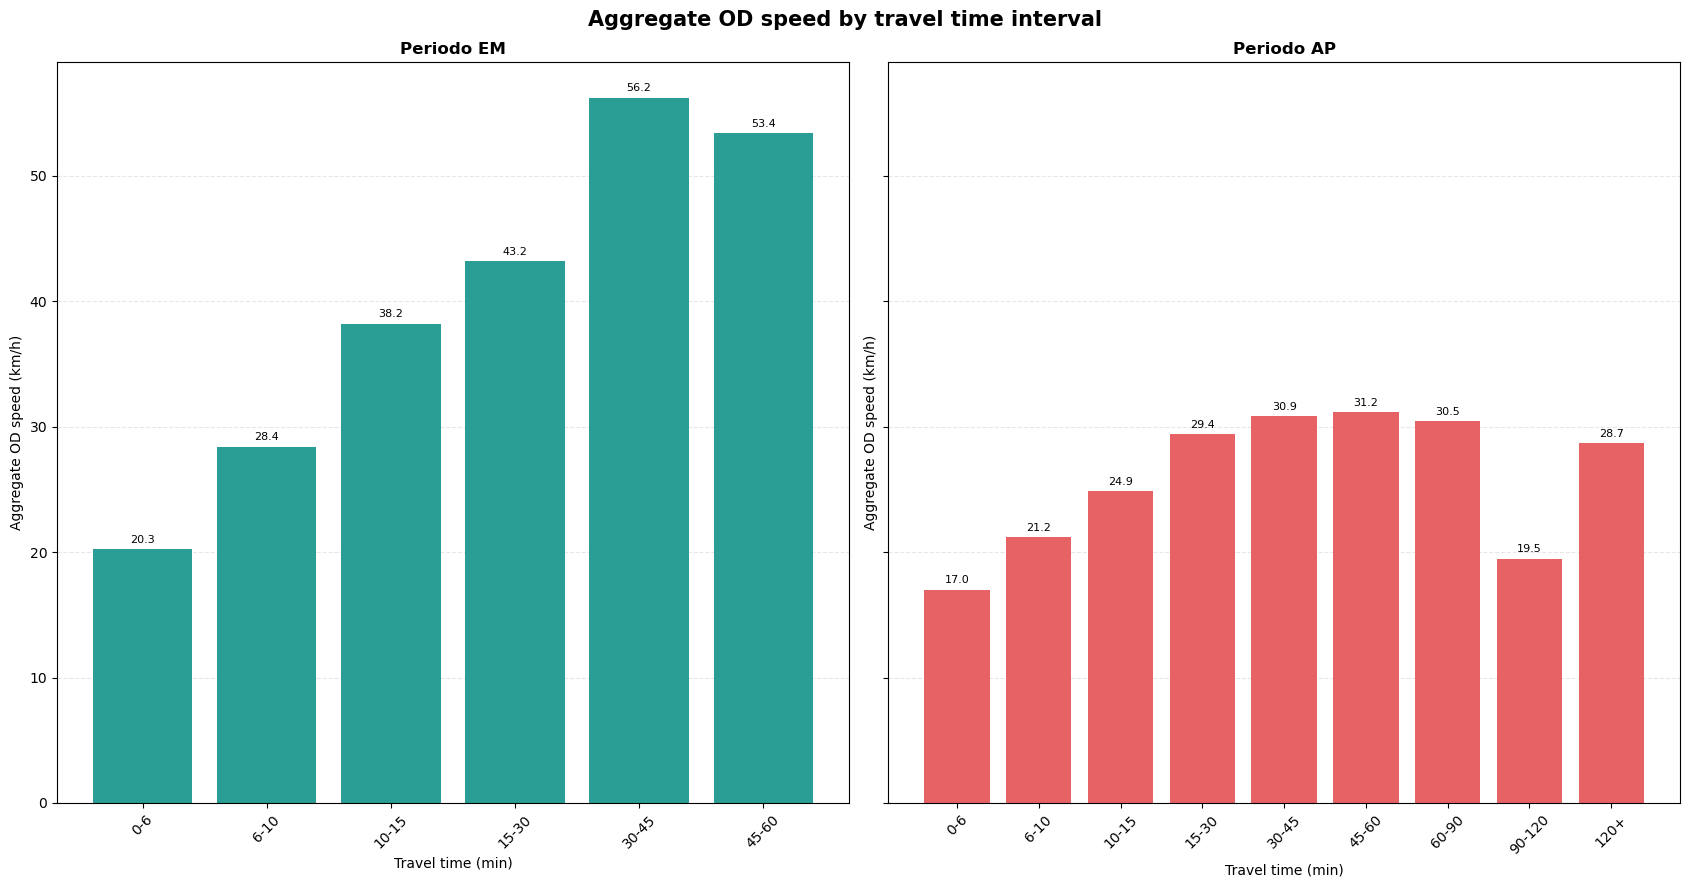

In [12]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 9),
    sharey=True
)

for ax, period in zip(axes.flat, periods):

    tabla = tablas_por_periodo[period]

    bars = ax.bar(
        tabla["Time bin"],
        tabla["Aggregate speed (km/h)"],
        color=colores_periodo[period]
    )

    ax.set_title(
        f"Periodo {period}",
        fontweight="bold"
    )

    ax.set_xlabel("Travel time (min)")
    ax.set_ylabel("Aggregate OD speed (km/h)")

    ax.tick_params(axis="x", rotation=45)

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

plt.suptitle(
    "Aggregate OD speed by travel time interval",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [13]:

suspicious_od = []

for period, df in datos_por_periodo.items():

    suspicious = df[
        (df["travel_time"] < 15) &
        (df["distance_km"] > 10) &
        (df["speed_kmh"] > 60)
    ].copy()

    suspicious_od.append(suspicious)

suspicious_od = pd.concat(
    suspicious_od,
    ignore_index=True
)

suspicious_od = suspicious_od.sort_values(
    "demand",
    ascending=False
)

columns = [
    "period",
    "Origin",
    "Destination",
    "demand",
    "travel_time",
    "distance_km",
    "speed_kmh"
]

display(
    suspicious_od[columns]
    .head(30)
    .round(2)
)


,period,Origin,Destination,demand,travel_time,distance_km,speed_kmh
0,EM,7211,6028,14.83,14.60,14.75,60.63
1,AP,1015,1028,0.98,12.06,13.49,67.12


In [14]:

summary_suspicious = []

for period, df in datos_por_periodo.items():

    suspicious = (
        (df["travel_time"] < 15) &
        (df["distance_km"] > 10) &
        (df["speed_kmh"] > 60)
    )

    total_trips = df["demand"].sum()
    suspicious_trips = df.loc[suspicious, "demand"].sum()

    summary_suspicious.append({
        "Period": period,
        "Total trips": total_trips,
        "Suspicious trips": suspicious_trips,
        "% Suspicious trips": (
            suspicious_trips / total_trips * 100
            if total_trips > 0 else np.nan
        )
    })

summary_suspicious = pd.DataFrame(summary_suspicious)

display(summary_suspicious.round(2))


,Period,Total trips,Suspicious trips,% Suspicious trips
0,EM,1153.2,14.83,1.29
1,AP,383080.4,0.98,0.00


In [15]:

resumen_general = []

for period, df in datos_por_periodo.items():

    pesos = df["demand"]

    tiempo_prom = np.average(
        df["travel_time"],
        weights=pesos
    )

    distancia_prom = np.average(
        df["distance_km"],
        weights=pesos
    )

    velocidad_agregada = (
        distancia_prom / tiempo_prom * 60
    )

    resumen_general.append({
        "Periodo": period,
        "Viajes": pesos.sum(),
        "TTC promedio (min)": tiempo_prom,
        "Distancia promedio (km)": distancia_prom,
        "Velocidad agregada (km/h)": velocidad_agregada,
        "% viajes < 15 min": (
            df.loc[df["travel_time"] < 15, "demand"].sum()
            / pesos.sum() * 100
        )
    })

resumen_general = pd.DataFrame(resumen_general)

display(resumen_general.round(2))


,Periodo,Viajes,TTC promedio (min),Distancia promedio (km),Velocidad agregada (km/h),% viajes < 15 min
0,EM,1153.2,15.46,10.76,41.74,42.60
1,AP,383080.4,23.00,10.91,28.47,42.77
